In [12]:
# Reload the .py files automatically when they are modified
%load_ext autoreload
%autoreload 2

import pandas as pd

from srccorentin.data_loading import load_data, json_to_dataframe, get_account_status, get_artist_genres
from srccorentin.music_features import (prepare_music_columns, build_user_features, build_artist_features,
                                add_music_features, add_genre_share)
from srccorentin.recency_features import add_days_ago, build_user_recency, build_artist_recency, add_recency_features
from srccorentin.csv_features import add_csv_features
from srccorentin.behaviour_features import add_ranking_features, add_behaviour_features
from srccorentin.preprocessing import prepare_X_y, split_by_user, build_preprocessor
from srccorentin.models import build_random_forest, build_logistic_regression, build_lightgbm
from srccorentin.evaluation import evaluate, plot_feature_importance, plot_lr_coefficients

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
# 1. LOAD THE DATA
train, test, data = load_data()

# Transform the JSON into a DataFrame: one row = one track played
df_music = json_to_dataframe(data)

# Dictionaries {user: activity status} and {artist: genres}
status = get_account_status(data)
artist_genres = get_artist_genres(data)

df_music.head()

,music_app_user_id,session_id,played_at,artist_id,genre,track_id,played_ms,track_ms,source,saved
0,M1213C172,S001,2026-09-30T21:22:16Z,A11,alternative,A11_6,132490,160000,autoplay,False
1,M1213C172,S002,2026-09-29T00:22:53Z,A08,jazz_funk,A08_6,198000,198000,autoplay,False
2,M1213C172,S003,2026-09-28T00:42:34Z,A08,jazz_funk,A08_12,223698,273000,search,True
3,M1213C172,S003,2026-09-28T17:59:57Z,A11,alternative,A11_12,205737,232000,search,False
4,M1213C172,S004,2026-09-27T21:36:03Z,A16,metal,A16_10,180541,196000,search,False


In [14]:
# 2. MUSIC FEATURES
# Add completion and searched columns
df_music = prepare_music_columns(df_music)

# One row = one user (plays, sessions, hours, rates, genres...)
df_activity = build_user_features(df_music)

# One row = one user x one artist
df_artist = build_artist_features(df_music)

df_activity.head()

,total_plays,total_sessions,listening_hours,completion_rate,save_rate,search_rate,unique_artists,unique_tracks,plays_per_session,alternative,...,jazz_funk_pct,metal_pct,psychedelic_pct,hip_hop_pct,electronic_pct,classical_pct,rnb_soul_pct,pop_pct,folk_country_pct,pop_rock_pct
music_app_user_id,,,,,,,,,,,,,,,,,,,,,
M000011A5,49,41,2.185755,0.743354,0.285714,0.612245,13,43,1.195122,13,...,0.081633,0.000000,0.122449,0.102041,0.122449,0.020408,0.040816,0.163265,0.040816,0.040816
M00001B55,100,65,4.371225,0.736342,0.300000,0.680000,11,53,1.538462,3,...,0.050000,0.000000,0.010000,0.060000,0.010000,0.110000,0.070000,0.420000,0.200000,0.040000
M00045894,44,35,2.188455,0.820784,0.409091,0.659091,9,30,1.257143,2,...,0.000000,0.045455,0.022727,0.000000,0.000000,0.000000,0.000000,0.181818,0.522727,0.181818
M0004CCB1,82,54,3.884244,0.798981,0.378049,0.609756,13,53,1.518519,1,...,0.109756,0.000000,0.012195,0.402439,0.036585,0.012195,0.219512,0.121951,0.048780,0.024390
M000704A9,41,35,1.532766,0.623419,0.292683,0.634146,13,32,1.171429,5,...,0.073171,0.024390,0.024390,0.219512,0.024390,0.024390,0.024390,0.170732,0.024390,0.268293


In [15]:
# Merge the music features into the CSVs
train_fe = add_music_features(train, status, df_activity, df_artist)
test_fe = add_music_features(test, status, df_activity, df_artist)

# Share of the user's listening matching the concert genres
train_fe = add_genre_share(train_fe, artist_genres)
test_fe = add_genre_share(test_fe, artist_genres)

train_fe[["artist_id", "artist_play_pct", "concert_genre_share"]].head(10)

,artist_id,artist_play_pct,concert_genre_share
0,A04,0.000000,0.423729
1,A02,0.177778,0.488889
2,A03,0.022222,0.133333
3,A01,0.022989,0.528736
4,A05,0.065217,0.630435
5,A01,NaN,NaN
6,A04,0.084746,0.440678
7,A01,0.000000,0.171429
8,A02,NaN,NaN
9,A03,0.270270,0.702703


In [16]:
# 3. CSV FEATURES (dates, prices, geography, missing values)
train_fe = add_csv_features(train_fe)
test_fe = add_csv_features(test_fe)

train_fe.head()

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,total_cost,cost_vs_typical,is_discounted,distance_km,same_city,travel_to_venue,spend_missing,Event_pages_missing,Has_music_app,travel_search_date_unknown
0,R2F019957,U2CFDCAAD,M1B01D2D7,23,postgraduate,2,Nantes,47.218,-1.554,pop,...,84.50,0.585464,0,507.182884,0,0,0,0,1,1
1,R0804D93A,U1FC01010,M1B2C63CC,51,undergraduate,5,Bordeaux,44.838,-0.579,pop,...,95.10,NaN,0,435.686287,0,0,1,0,1,1
2,R367FE81E,U0C605712,M3AEF638D,32,secondary,1,Lyon,45.764,4.835,classical,...,155.50,1.725477,1,435.686287,0,0,0,0,1,1
3,R344BBE29,U25D1DD8A,M00C580ED,24,secondary,2,Paris,48.857,2.352,jazz_funk,...,94.04,0.815470,0,0.000000,1,0,0,0,1,1
4,R004ABDEB,U1600BC92,M29AC37E6,21,secondary,3,Bordeaux,44.838,-0.579,NaN,...,105.70,NaN,0,275.134450,0,0,1,0,1,0


In [17]:
# 4. RECENCY FEATURES
# How many days ago each track was played
df_music = add_days_ago(df_music, data["history_ends_before"])

# Recency per user and per user x artist
df_recency = build_user_recency(df_music)
df_artist_recency = build_artist_recency(df_music)

# Merge into the CSVs
train_fe = add_recency_features(train_fe, df_recency, df_artist_recency)
test_fe = add_recency_features(test_fe, df_recency, df_artist_recency)

df_recency.head()


,days_since_last_play,plays_7d,plays_30d
music_app_user_id,,,
M000011A5,2.814861,5.0,18
M00001B55,0.441169,7.0,37
M00045894,0.272257,7.0,19
M0004CCB1,1.543461,6.0,29
M000704A9,1.497650,8.0,19


In [18]:
# 5. RANKING AND BEHAVIOUR FEATURES
train_fe = add_ranking_features(train_fe)
test_fe = add_ranking_features(test_fe)

train_fe = add_behaviour_features(train_fe)
test_fe = add_behaviour_features(test_fe)

# Verify that merging did not create additional rows
assert len(train_fe) == len(train)
assert len(test_fe) == len(test)
print(train_fe.shape, test_fe.shape)

(30000, 121) (20000, 120)


In [19]:
# 6. PREPARE THE DATA FOR THE MODELS
# X / y / groups, genre encoding, same columns in train and test
X, y, groups, X_test = prepare_X_y(train_fe, test_fe)

# 80% of users for training, 20% for validation
X_train, X_valid, y_train, y_valid = split_by_user(X, y, groups)

# Imputation + one-hot encoding, shared by all models
preprocessor = build_preprocessor(X_train)

print("Number of features:", X.shape[1])
print(X_train.shape, X_valid.shape)

Number of features: 119
(24000, 119) (6000, 119)


{'Model': 'Random Forest', 'Accuracy': 0.8318333333333333, 'ROC-AUC': 0.9108563924141359, 'F1 (0.5)': 0.7353789666928927, 'Best threshold': 0.31, 'Best F1': 0.7636441770519983}


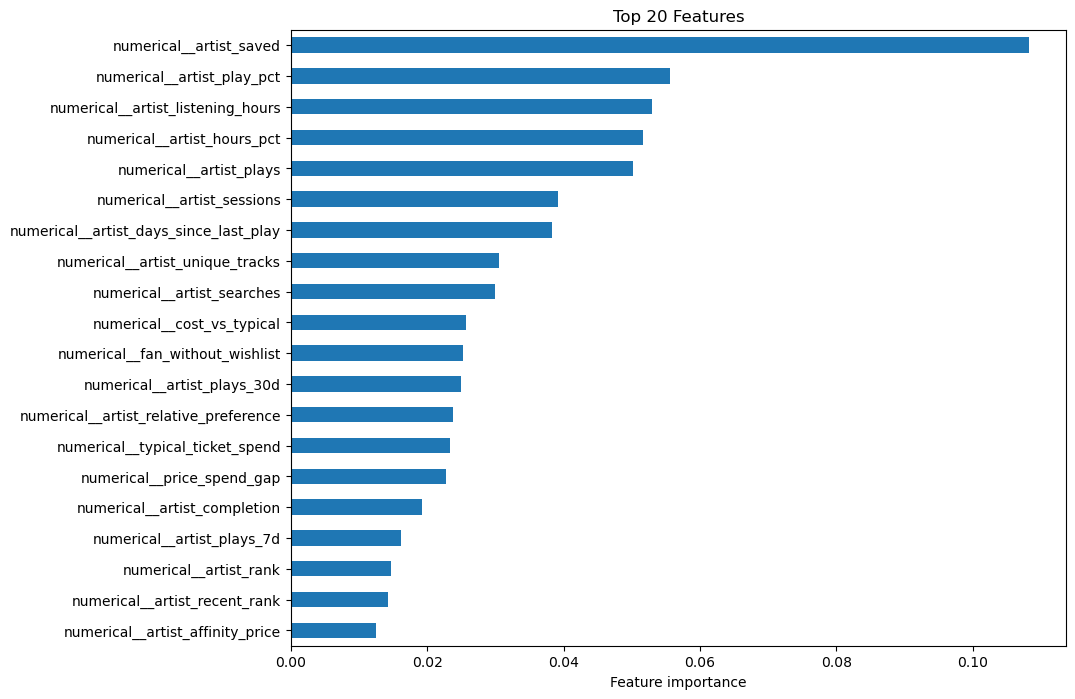

In [20]:
# 7. RANDOM FOREST
model_rf = build_random_forest(preprocessor)
model_rf.fit(X_train, y_train)

res_rf = evaluate(model_rf, X_valid, y_valid, "Random Forest")
plot_feature_importance(model_rf)

{'Model': 'Logistic Regression', 'Accuracy': 0.842, 'ROC-AUC': 0.9124458938966197, 'F1 (0.5)': 0.7564234326824255, 'Best threshold': 0.39, 'Best F1': 0.7749408983451537}


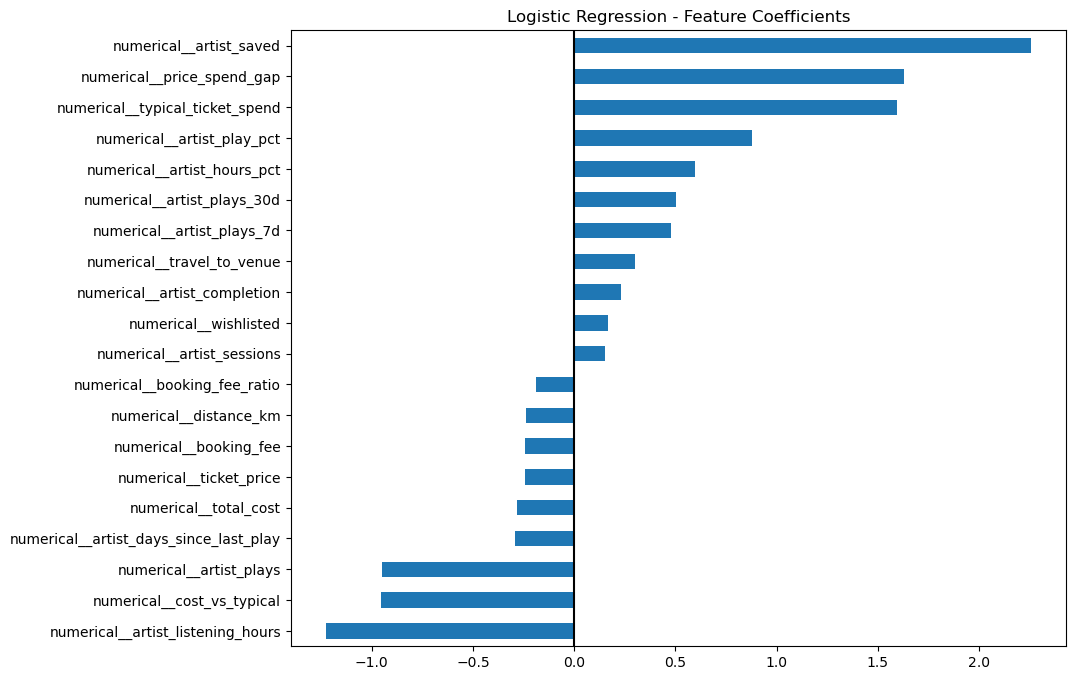

In [21]:
# 8. LOGISTIC REGRESSION
model_lr = build_logistic_regression(preprocessor)
model_lr.fit(X_train, y_train)

res_lr = evaluate(model_lr, X_valid, y_valid, "Logistic Regression")
plot_lr_coefficients(model_lr)

{'Model': 'LightGBM', 'Accuracy': 0.8563333333333333, 'ROC-AUC': 0.9322418189995364, 'F1 (0.5)': 0.784607696151924, 'Best threshold': 0.45, 'Best F1': 0.794011108427916}


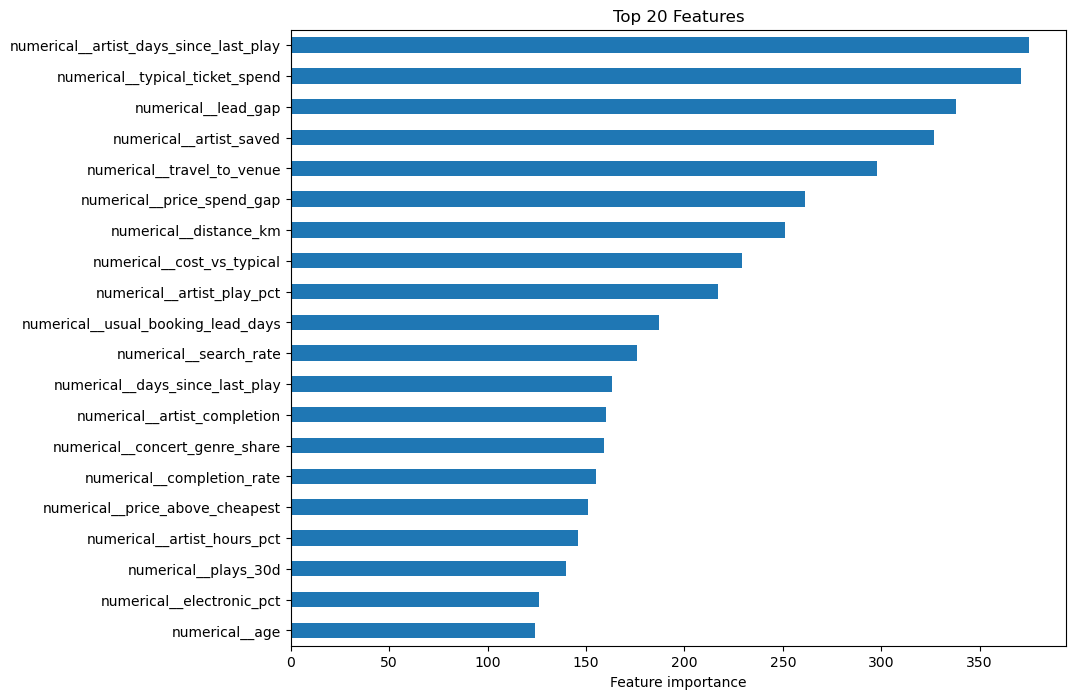

In [22]:
# 9. LIGHTGBM (pip install lightgbm if needed)
model_lgbm = build_lightgbm(preprocessor)
model_lgbm.fit(X_train, y_train)

res_lgbm = evaluate(model_lgbm, X_valid, y_valid, "LightGBM")
plot_feature_importance(model_lgbm)

In [23]:
# 10. COMPARE THE THREE MODELS
pd.DataFrame([res_rf, res_lr, res_lgbm]).set_index("Model").round(4)

,Accuracy,ROC-AUC,F1 (0.5),Best threshold,Best F1
Model,,,,,
Random Forest,0.8318,0.9109,0.7354,0.31,0.7636
Logistic Regression,0.8420,0.9124,0.7564,0.39,0.7749
LightGBM,0.8563,0.9322,0.7846,0.45,0.7940
